In [1]:
import requests
import pandas as pd

series = [
    "BD.CDN.2YR.DQ.YLD",
    "BD.CDN.3YR.DQ.YLD",
    "BD.CDN.5YR.DQ.YLD",
    "BD.CDN.7YR.DQ.YLD",
    "BD.CDN.10YR.DQ.YLD",
    "BD.CDN.LONG.DQ.YLD",
]

url = ("https://www.bankofcanada.ca/valet/observations/"
       + ",".join(series) + "/json?start_date=2015-01-01")
data = requests.get(url).json()

#print(data.keys())
#print(data["observations"][0])

In [3]:
rows = []
for obs in data["observations"]:
    row = {"date": obs["d"]}
    for s in series:
        row[s] = obs.get(s, {}).get("v")    # read this series' value for this day
    rows.append(row)

df = pd.DataFrame(rows)
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date").sort_index()

for s in series:
    df[s] = pd.to_numeric(df[s], errors="coerce")

df = df.rename(columns={
    "BD.CDN.2YR.DQ.YLD": "2yr",
    "BD.CDN.3YR.DQ.YLD": "3yr",
    "BD.CDN.5YR.DQ.YLD": "5yr",
    "BD.CDN.7YR.DQ.YLD": "7yr",
    "BD.CDN.10YR.DQ.YLD": "10yr",
    "BD.CDN.LONG.DQ.YLD": "long",
})

print(df.shape)
print(df.isna().sum())
df.tail()

(2951, 6)
2yr     0
3yr     0
5yr     0
7yr     0
10yr    0
long    0
dtype: int64


,2yr,3yr,5yr,7yr,10yr,long
date,,,,,,
2026-10-23,3.33,3.44,3.56,3.66,3.83,4.12
2026-10-26,3.37,3.47,3.58,3.66,3.84,4.13
2026-10-27,3.36,3.45,3.57,3.66,3.83,4.12
2026-10-28,3.41,3.51,3.62,3.70,3.87,4.15
2026-10-29,3.36,3.46,3.58,3.67,3.84,4.13


In [10]:
# Save the DataFrame to a CSV file
df.to_csv('../data/yields.csv')

# Calculate the 10-year minus 2-year yield spread
# Return for 10-year should be higher than 2-year, so the spread should be positive. If the spread is negative, it is called an inverted yield curve.
df["spread_10_2"] = df["10yr"] - df["2yr"]

inverted = df[df["spread_10_2"] < 0]
print(len(inverted))
inverted.index.year.value_counts().sort_index()

703


date
2019    111
2020     43
2022    118
2023    248
2024    183
Name: count, dtype: int64

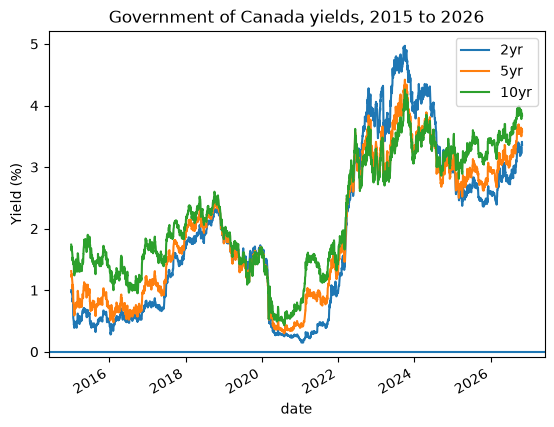

In [11]:
import matplotlib.pyplot as plt
df[["2yr", "5yr", "10yr"]].plot()
plt.axhline(0)
plt.ylabel("Yield (%)")
plt.title("Government of Canada yields, 2015 to 2026")
plt.show()

Observations:

- The 10-year minus 2-year spread was positive on every business day in 2015 to 2018, 2021, and 2025 to October 2026. It was inverted on 703 of 2800 days since 2015.
- The 2-year yield rose from 0.3% in 2021 to 5% in 2024, about 470 bps.
- In 2023 the curve was inverted on 248 of about 250 business days, the longest stretch in the data.
- Yields fell to about 0.3% in mid 2020, then rose through 2021 and 2022.
- On Oct 29, 2026 the spread was +48 bps, a normal curve.